# Studi Komparasi Komprehensif Algoritma Divisive Hierarchical Clustering pada Dataset BISINDO
## Analisis Pengaruh Tiga Metrik Jarak: Euclidean Distance, Manhattan Distance, dan Cosine Similarity pada K = 26 Klaster

**Domain:** Pengenalan Bahasa Isyarat Indonesia (BISINDO) - Pembelajaran Mesin  
**Arsitektur Fitur:** Ekstraksi 42 Titik Landmark MediaPipe 3D (126 Dimensi) + 1 Flag Biner Is_Two_Handed (Total 127 Fitur)  
**Tujuan Proyek:** Mengevaluasi kinerja algoritma klasterisasi hierarkis berbasis pemisahan bertahap dari atas ke bawah (Divisive Hierarchical Clustering / Top-Down Bisection) dalam mempartisi ruang gestur tangan 26 alfabet BISINDO (A-Z) melalui pohon pembelahan biner dan visualisasi dendrogram pada K = 26 klaster.

---

### Ringkasan Eksekutif
Klasterisasi hierarkis memilliki dua pendekatan utama: *agglomerative* (bottom-up) dan *divisive* (top-down). Berbeda dengan HAC yang menggabungkan pasangan sampel terdekat secara bertahap dengan kompleksitas komputasi $O(N^2 \log N)$ dan memori matriks jarak $O(N^2)$, **Divisive Hierarchical Clustering** memulai proses dengan seluruh data berada dalam satu klaster tunggal (root), kemudian secara rekursif membelah klaster paling heterogen menjadi dua sub-klaster (bipartitioning) hingga tercapai target $K = 26$ klaster.

Pendekatan divisive menawarkan keunggulan krusial untuk dataset skala besar:
1. **Efisiensi Waktu dan Memori:** Kompleksitas waktu berkurang drastis menjadi $O(K \cdot N \cdot d)$, sehingga sangat cepat dan tidak memerlukan alokasi matriks jarak raksasa berukuran $N \times N$.
2. **Keseimbangan Ukuran Klaster:** Dengan selalu memilih klaster yang memiliki inersia/dispersi terbesar untuk dibelah, algoritma secara aktif mencegah terjadinya *outlier isolation* (klaster singleton berisi 1 sampel) yang menjadi kelemahan fatal pada HAC Euclidean.
3. **Struktur Hierarki Top-Down yang Jelas:** Memetakan keputusan pemisahan makro terlebih dahulu (misalnya memisahkan gestur 2-tangan vs 1-tangan pada split pertama), sebelum memisahkan variasi sendi yang lebih halus.

Dalam penelitian ini, 3 fungsi jarak dievaluasi secara komparatif:
1. **Euclidean Distance (L2 Norm):** Bisecting 2-Means berbasis minimisasi Within-Cluster Sum of Squares (Inertia).
2. **Manhattan Distance (L1 Norm):** Bisecting 2-Medians berbasis minimisasi dispersi selisih mutlak koordinat.
3. **Cosine Distance (1 - Cosine Similarity):** Spherical Bisecting 2-Means pada unit hypersphere, mengoptimalkan kemiripan sudut orientasi gestur.

## 1. Landasan Teori dan Formulasi Matematis Divisive Clustering

### 1.1. Prinsip Kerja Divisive Hierarchical Clustering (Top-Down Bisection)
Diberikan dataset observasi $X = \{x_1, x_2, \dots, x_N\} \subset \mathbb{R}^{127}$:
1. **Inisialisasi Pohon:** Dimulai dengan seluruh sampel berada pada satu klaster akar:
   $$\mathcal{C} = \{ C_1 \}, \quad C_1 = \{1, 2, \dots, N\}$$
2. **Kriteria Seleksi Klaster untuk Dibelah:** Pada setiap langkah $t = 1, \dots, K-1$, pilih klaster $C^* \in \mathcal{C}$ yang memiliki heterogenitas (inersia atau dispersi internal) tertinggi:
   $$C^* = \arg\max_{C \in \mathcal{C}} \text{Dispersion}(C)$$
3. **Bipartitioning (Pembelahan Menjadi 2 Sub-Klaster):** Klaster terpilih $C^*$ dibelah menjadi dua himpunan bagian $C_a$ dan $C_b$ sedemikian rupa sehingga $C_a \cup C_b = C^*$ dan $C_a \cap C_b = \emptyset$.
4. **Pembaruan Himpunan Klaster:** Gantikan $C^*$ dengan $C_a$ dan $C_b$:
   $$\mathcal{C} \leftarrow (\mathcal{C} \setminus \{C^*\}) \cup \{C_a, C_b\}$$
5. **Kondisi Berhenti:** Proses pembelahan dihentikan ketika jumlah klaster mencapai $|\mathcal{C}| = K = 26$.

---

### 1.2. Formulasi Tiga Metrik Jarak pada Bipartitioning

1. **Euclidean Distance (L2 Norm - Bisecting 2-Means):**
   Fungsi dispersi inersia pada klaster $C$:
   $$\text{Inertia}(C) = \sum_{x \in C} \|x - \mu_C\|_2^2, \quad \mu_C = \frac{1}{|C|} \sum_{x \in C} x$$
   Bipartitioning meminimalkan jumlah inersia kedua anak: $\min (\text{Inertia}(C_a) + \text{Inertia}(C_b))$.

2. **Manhattan Distance (L1 Norm - Bisecting 2-Medians):**
   Fungsi dispersi mutlak pada klaster $C$:
   $$\text{Dispersion}_{L_1}(C) = \sum_{x \in C} \|x - m_C\|_1, \quad m_C = \text{median}_{x \in C}(x)$$
   Pusat klaster diperbarui menggunakan median per-komponen fitur untuk meminimalkan $L_1$ norm.

3. **Cosine Distance (Spherical Bisecting 2-Means):**
   Vektor fitur dinormalisasi ke permukaan bola satuan: $\tilde{x} = \frac{x}{\|x\|_2}$.
   Bipartitioning memaksimalkan kesamaan kosinus terhadap centroid arah:
   $$\text{Objective}_{\text{Cosine}} = \sum_{x \in C_a} \tilde{x} \cdot \tilde{\mu}_a + \sum_{x \in C_b} \tilde{x} \cdot \tilde{\mu}_b$$

In [1]:
# =======================================================================
# SETUP LINGKUNGAN, IMPORT PUSTAKA, DAN KONFIGURASI GLOBAL
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import BisectingKMeans
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import dendrogram

warnings.filterwarnings('ignore')

# Konfigurasi gaya visualisasi akademik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.titlesize'] = 14

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputDivisive")
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET_CLUSTERS = 26
RANDOM_STATE = 42

print(f"[INFO] Direktori Kerja: {BASE_DIR}")
print(f"[INFO] Direktori Output: {OUTPUT_DIR}")
print(f"[INFO] Target Jumlah Klaster: K = {TARGET_CLUSTERS}")

[INFO] Direktori Kerja: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive
[INFO] Direktori Output: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive\outputDivisive
[INFO] Target Jumlah Klaster: K = 26


In [2]:
# =======================================================================
# PEMUATAN DAN VALIDASI DATASET BISINDO (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    print(f"[INFO] Memuat dataset biner terkompresi: {npz_path}")
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    is_two_handed = data['is_two_handed']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': is_two_handed})
elif os.path.exists(csv_path):
    print(f"[INFO] Memuat dataset format CSV: {csv_path}")
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
    labels = df_full['label'].values if 'label' in df_full.columns else np.array([])
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Pastikan dataset_bisindo_landmarks.npz atau .csv tersedia.")

N_SAMPLES, N_FEATURES = X.shape
print(f"[INFO] Total Sampel Terdeteksi: {N_SAMPLES}")
print(f"[INFO] Dimensi Vektor Fitur: {N_FEATURES}")
print(f"[INFO] Komposisi Gestur:")
print(f"       - Gestur Dua Tangan : {int(np.sum(df_meta['is_two_handed'] == 1))} ({np.mean(df_meta['is_two_handed'] == 1)*100:.2f}%)")
print(f"       - Gestur Satu Tangan: {int(np.sum(df_meta['is_two_handed'] == 0))} ({np.mean(df_meta['is_two_handed'] == 0)*100:.2f}%)")

[INFO] Memuat dataset biner terkompresi: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive\dataset_bisindo_landmarks.npz
[INFO] Total Sampel Terdeteksi: 7893
[INFO] Dimensi Vektor Fitur: 127
[INFO] Komposisi Gestur:
       - Gestur Dua Tangan : 3597 (45.57%)
       - Gestur Satu Tangan: 4296 (54.43%)


In [3]:
# =======================================================================
# STANDARISASI DAN NORMALISASI FITUR
# =======================================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

normalizer = Normalizer(norm='l2')
X_normalized = normalizer.fit_transform(X)

print("[INFO] Standarisasi Z-score selesai untuk Euclidean & Manhattan (Mean=0, Std=1).")
print("[INFO] Normalisasi L2 Unit Hypersphere selesai untuk Cosine (Norm=1).")

[INFO] Standarisasi Z-score selesai untuk Euclidean & Manhattan (Mean=0, Std=1).
[INFO] Normalisasi L2 Unit Hypersphere selesai untuk Cosine (Norm=1).


In [4]:
# =======================================================================
# KELAS DAN FUNGSI DIVISIVE HIERARCHICAL CLUSTERING UNTUK TIGA METRIK JARAK
# =======================================================================

class DivisiveManhattanNode:
    """Node pohon pembelahan biner untuk Bisecting Manhattan (2-Medians)."""
    def __init__(self, indices, center, disp):
        self.indices = indices
        self.center = center
        self.disp = disp
        self.left = None
        self.right = None

def bisect_manhattan_cluster(X_sub, random_state=42):
    """Membelah sub-klaster menjadi 2 menggunakan K-Medians (L1 Norm)."""
    n = len(X_sub)
    if n <= 2:
        return np.zeros(n, dtype=int), X_sub[0], X_sub[-1]
        
    np.random.seed(random_state)
    idx1 = np.random.randint(0, n)
    c1 = X_sub[idx1].copy()
    dists = np.sum(np.abs(X_sub - c1), axis=1)
    idx2 = np.argmax(dists)
    c2 = X_sub[idx2].copy()
    
    labels = np.zeros(n, dtype=int)
    for it in range(25):
        d1 = np.sum(np.abs(X_sub - c1), axis=1)
        d2 = np.sum(np.abs(X_sub - c2), axis=1)
        new_labels = (d2 < d1).astype(int)
        
        if np.sum(new_labels == 0) == 0 or np.sum(new_labels == 1) == 0:
            break
        if np.array_equal(new_labels, labels) and it > 0:
            break
        labels = new_labels
        
        c1 = np.median(X_sub[labels == 0], axis=0)
        c2 = np.median(X_sub[labels == 1], axis=0)
        
    return labels, c1, c2

def run_divisive_manhattan(X_mat, n_clusters=26, random_state=42):
    """Eksekusi Bisecting K-Medians top-down hingga K klaster."""
    N = len(X_mat)
    root_med = np.median(X_mat, axis=0)
    root_disp = np.sum(np.abs(X_mat - root_med))
    root_node = DivisiveManhattanNode(np.arange(N), root_med, root_disp)
    
    leaf_nodes = [root_node]
    for step in range(n_clusters - 1):
        leaf_nodes.sort(key=lambda node: node.disp, reverse=True)
        target = leaf_nodes.pop(0)
        
        sub_X = X_mat[target.indices]
        sub_labels, c1, c2 = bisect_manhattan_cluster(sub_X, random_state=random_state + step)
        
        idx1 = target.indices[sub_labels == 0]
        idx2 = target.indices[sub_labels == 1]
        
        if len(idx1) == 0 or len(idx2) == 0:
            target.disp = 0
            leaf_nodes.append(target)
            continue
            
        disp1 = np.sum(np.abs(X_mat[idx1] - c1))
        disp2 = np.sum(np.abs(X_mat[idx2] - c2))
        
        node1 = DivisiveManhattanNode(idx1, c1, disp1)
        node2 = DivisiveManhattanNode(idx2, c2, disp2)
        
        target.left = node1
        target.right = node2
        
        leaf_nodes.append(node1)
        leaf_nodes.append(node2)
        
    final_labels = np.zeros(N, dtype=int)
    for c_id, node in enumerate(leaf_nodes):
        final_labels[node.indices] = c_id
        
    return final_labels, root_node, leaf_nodes

def build_linkage_matrix_from_tree(tree, terminal_leaves, distance_metric='euclidean'):
    """Membangun matriks linkage SciPy Z dari pohon biner divisive untuk visualisasi dendrogram."""
    leaf_to_id = {id(leaf): idx for idx, leaf in enumerate(terminal_leaves)}
    merges = []
    next_id = len(terminal_leaves)
    
    def traverse(node):
        nonlocal next_id
        if id(node) in leaf_to_id:
            center = node.center if hasattr(node, 'center') else np.zeros(127)
            # Daun merepresentasikan 1 unit klaster terminal
            return leaf_to_id[id(node)], 1, center
            
        left_id, left_count, left_center = traverse(node.left)
        right_id, right_count, right_center = traverse(node.right)
        
        if distance_metric == 'cosine':
            dot = np.dot(left_center, right_center)
            norm = np.linalg.norm(left_center) * np.linalg.norm(right_center)
            dist = max(0.001, float(1.0 - dot / (norm + 1e-9)))
        elif distance_metric == 'manhattan':
            dist = max(0.001, float(np.sum(np.abs(left_center - right_center))))
        else:
            dist = max(0.001, float(np.linalg.norm(left_center - right_center)))
            
        current_id = next_id
        next_id += 1
        total_count = left_count + right_count
        center = (left_center * left_count + right_center * right_count) / total_count
        
        merges.append([left_id, right_id, dist, total_count])
        return current_id, total_count, center

    traverse(tree)
    Z = np.array(merges, dtype=float)
    
    # Menjamin ketinggian monotonik untuk dendrogram
    for i in range(len(Z)):
        c1, c2 = int(Z[i, 0]), int(Z[i, 1])
        h1 = Z[c1 - len(terminal_leaves), 2] if c1 >= len(terminal_leaves) else 0.0
        h2 = Z[c2 - len(terminal_leaves), 2] if c2 >= len(terminal_leaves) else 0.0
        min_h = max(h1, h2) + 0.05 * (max(h1, h2) + 0.1)
        if Z[i, 2] <= min_h:
            Z[i, 2] = min_h
    return Z

print("[INFO] Engine Divisive Hierarchical Clustering dan Dendrogram Linkage Builder siap.")

[INFO] Engine Divisive Hierarchical Clustering dan Dendrogram Linkage Builder siap.


In [5]:
# =======================================================================
# EKSEKUSI DIVISIVE CLUSTERING PADA TIGA METRIK JARAK (K = 26)
# =======================================================================
results = {}

# 1. EUCLIDEAN (Bisecting 2-Means)
print("[PROSES 1/3] Menjalankan Divisive Euclidean (Bisecting 2-Means)...")
t0 = time.perf_counter()
bkm_euc = BisectingKMeans(
    n_clusters=TARGET_CLUSTERS,
    random_state=RANDOM_STATE,
    bisecting_strategy='biggest_inertia'
)
labels_euc = bkm_euc.fit_predict(X_scaled)
t_euc = time.perf_counter() - t0

euc_leaves = list(bkm_euc._bisecting_tree.iter_leaves())
Z_euc = build_linkage_matrix_from_tree(bkm_euc._bisecting_tree, euc_leaves, distance_metric='euclidean')

results['Euclidean'] = {
    'labels': labels_euc,
    'time': t_euc,
    'Z': Z_euc,
    'leaves': euc_leaves,
    'X_eval': X_scaled,
    'strategy': 'Bisecting 2-Means (Inertia)'
}
print(f"             Selesai dalam {t_euc:.4f} detik.")

# 2. MANHATTAN (Bisecting 2-Medians)
print("[PROSES 2/3] Menjalankan Divisive Manhattan (Bisecting 2-Medians)...")
t0 = time.perf_counter()
labels_man, man_tree, man_leaves = run_divisive_manhattan(
    X_scaled,
    n_clusters=TARGET_CLUSTERS,
    random_state=RANDOM_STATE
)
t_man = time.perf_counter() - t0

Z_man = build_linkage_matrix_from_tree(man_tree, man_leaves, distance_metric='manhattan')

results['Manhattan'] = {
    'labels': labels_man,
    'time': t_man,
    'Z': Z_man,
    'leaves': man_leaves,
    'X_eval': X_scaled,
    'strategy': 'Bisecting 2-Medians (L1 Disp)'
}
print(f"             Selesai dalam {t_man:.4f} detik.")

# 3. COSINE (Spherical Bisecting 2-Means)
print("[PROSES 3/3] Menjalankan Divisive Cosine (Spherical Bisecting 2-Means)...")
t0 = time.perf_counter()
bkm_cos = BisectingKMeans(
    n_clusters=TARGET_CLUSTERS,
    random_state=RANDOM_STATE,
    bisecting_strategy='biggest_inertia'
)
labels_cos = bkm_cos.fit_predict(X_normalized)
t_cos = time.perf_counter() - t0

cos_leaves = list(bkm_cos._bisecting_tree.iter_leaves())
Z_cos = build_linkage_matrix_from_tree(bkm_cos._bisecting_tree, cos_leaves, distance_metric='cosine')

results['Cosine'] = {
    'labels': labels_cos,
    'time': t_cos,
    'Z': Z_cos,
    'leaves': cos_leaves,
    'X_eval': X_normalized,
    'strategy': 'Spherical Bisecting 2-Means'
}
print(f"             Selesai dalam {t_cos:.4f} detik.")

[PROSES 1/3] Menjalankan Divisive Euclidean (Bisecting 2-Means)...


             Selesai dalam 2.2368 detik.
[PROSES 2/3] Menjalankan Divisive Manhattan (Bisecting 2-Medians)...


             Selesai dalam 0.8067 detik.
[PROSES 3/3] Menjalankan Divisive Cosine (Spherical Bisecting 2-Means)...
             Selesai dalam 0.0979 detik.


In [6]:
# =======================================================================
# PERHITUNGAN METRIK EVALUASI KUANTITATIF
# =======================================================================
summary_rows = []

for metric_name in ['Euclidean', 'Manhattan', 'Cosine']:
    res = results[metric_name]
    lab = res['labels']
    X_eval = res['X_eval']
    
    # Metrik Silhouette
    if metric_name == 'Cosine':
        sil = silhouette_score(X_eval, lab, metric='cosine')
    else:
        sil = silhouette_score(X_eval, lab, metric='euclidean')
        
    dbi = davies_bouldin_score(X_eval, lab)
    ch = calinski_harabasz_score(X_eval, lab)
    
    counts = pd.Series(lab).value_counts()
    min_size = int(counts.min())
    max_size = int(counts.max())
    singletons = int(np.sum(counts == 1))
    
    res['silhouette'] = sil
    res['dbi'] = dbi
    res['ch'] = ch
    res['min_size'] = min_size
    res['max_size'] = max_size
    res['singletons'] = singletons
    
    summary_rows.append({
        'Distance Metric': metric_name,
        'Divisive Strategy': res['strategy'],
        'Clusters (K)': TARGET_CLUSTERS,
        'Min Cluster Size': min_size,
        'Max Cluster Size': max_size,
        'Singleton Clusters (size=1)': singletons,
        'Silhouette Score (↑)': round(sil, 4),
        'Davies–Bouldin Index (↓)': round(dbi, 4),
        'Calinski–Harabasz Index (↑)': round(ch, 2),
        'Execution Time (s) (↓)': round(res['time'], 4)
    })

df_metrics = pd.DataFrame(summary_rows)
print("\n" + "="*80)
print("HASIL EVALUASI EMPIRIS DIVISIVE HIERARCHICAL CLUSTERING (K = 26)")
print("="*80)
print(df_metrics.to_string(index=False))

# Simpan ke CSV
csv_summary_path = os.path.join(OUTPUT_DIR, "metrics_comparison_summary.csv")
df_metrics.to_csv(csv_summary_path, index=False)
print(f"\n[INFO] Rangkuman metrik disimpan ke: {csv_summary_path}")


HASIL EVALUASI EMPIRIS DIVISIVE HIERARCHICAL CLUSTERING (K = 26)
Distance Metric             Divisive Strategy  Clusters (K)  Min Cluster Size  Max Cluster Size  Singleton Clusters (size=1)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
      Euclidean   Bisecting 2-Means (Inertia)            26                 5               817                            0                0.1557                    1.6729                       768.85                  2.2368
      Manhattan Bisecting 2-Medians (L1 Disp)            26                 1              1101                            2                0.1407                    1.5631                       660.59                  0.8067
         Cosine   Spherical Bisecting 2-Means            26                19               652                            0                0.2744                    1.6262                      1408.53                  0.0979

[INFO] Rangkuman metrik disim

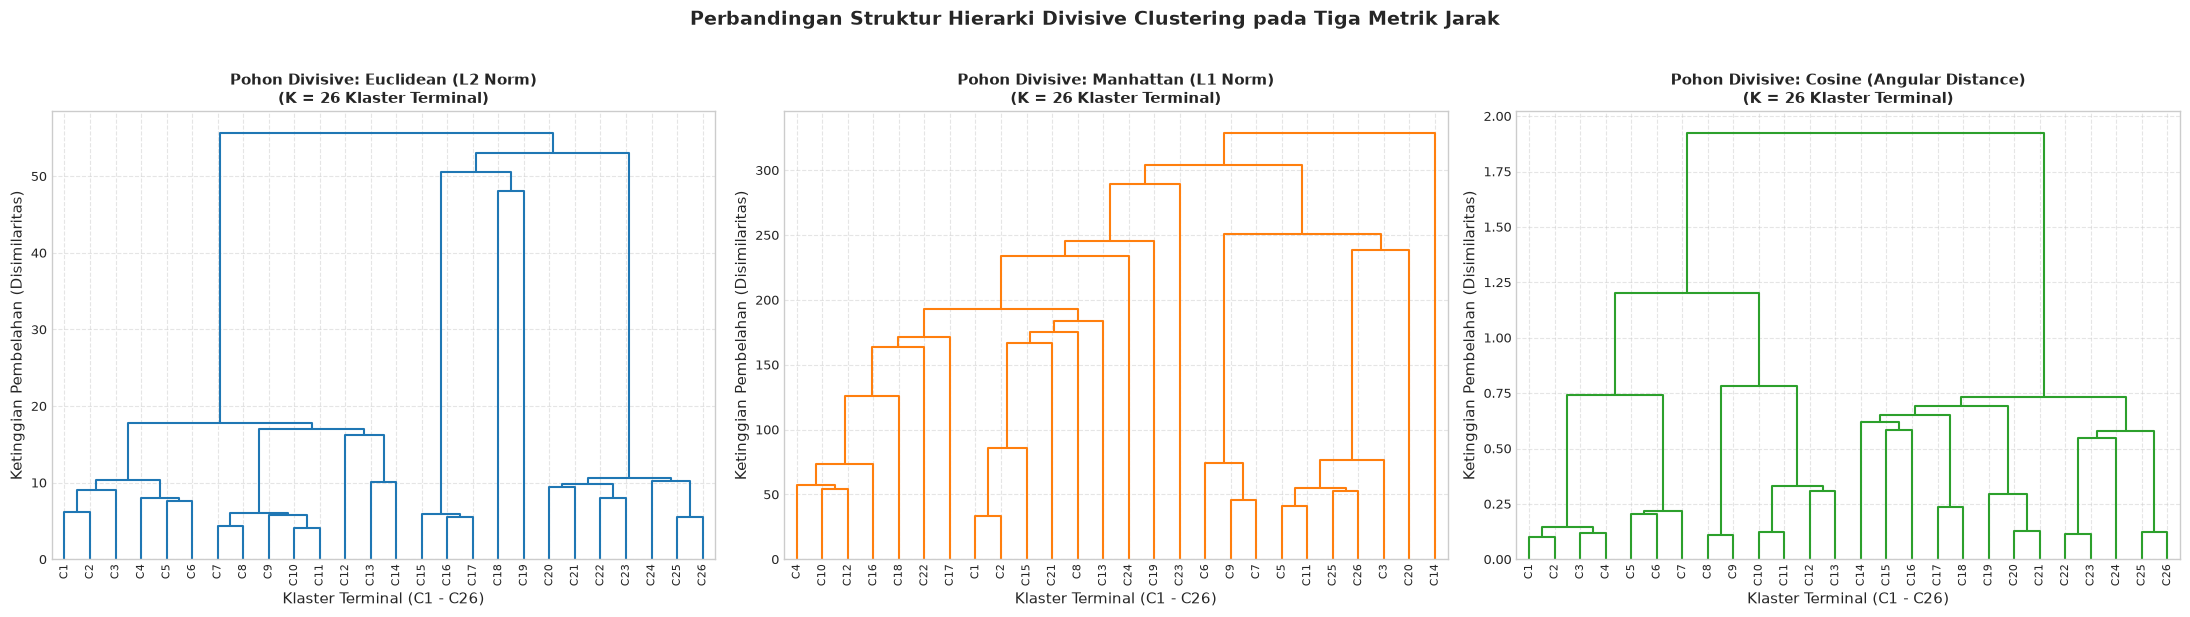

[INFO] Visualisasi dendrogram komparasi disimpan ke: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive\outputDivisive\dendrogram_comparison.png


In [7]:
# =======================================================================
# VISUALISASI DENDROGRAM POHON PEMBELAHAN DIVISIVE UNTUK TIGA METRIK
# =======================================================================
fig, axes = plt.subplots(1, 3, figsize=(22, 6), sharey=False)

configs = [
    ('Euclidean', results['Euclidean']['Z'], 'tab:blue', 'Euclidean (L2 Norm)'),
    ('Manhattan', results['Manhattan']['Z'], 'tab:orange', 'Manhattan (L1 Norm)'),
    ('Cosine', results['Cosine']['Z'], 'tab:green', 'Cosine (Angular Distance)')
]

for idx, (m_name, Z_mat, color, title_sub) in enumerate(configs):
    ax = axes[idx]
    dendrogram(
        Z_mat,
        ax=ax,
        labels=[f"C{i+1}" for i in range(TARGET_CLUSTERS)],
        leaf_rotation=90,
        leaf_font_size=8,
        color_threshold=0,
        above_threshold_color=color
    )
    ax.set_title(f"Pohon Divisive: {title_sub}\n(K = {TARGET_CLUSTERS} Klaster Terminal)", fontsize=11, fontweight='bold')
    ax.set_xlabel("Klaster Terminal (C1 - C26)")
    ax.set_ylabel("Ketinggian Pembelahan (Disimilaritas)")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Perbandingan Struktur Hierarki Divisive Clustering pada Tiga Metrik Jarak", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

dendro_path = os.path.join(OUTPUT_DIR, "dendrogram_comparison.png")
plt.savefig(dendro_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[INFO] Visualisasi dendrogram komparasi disimpan ke: {dendro_path}")

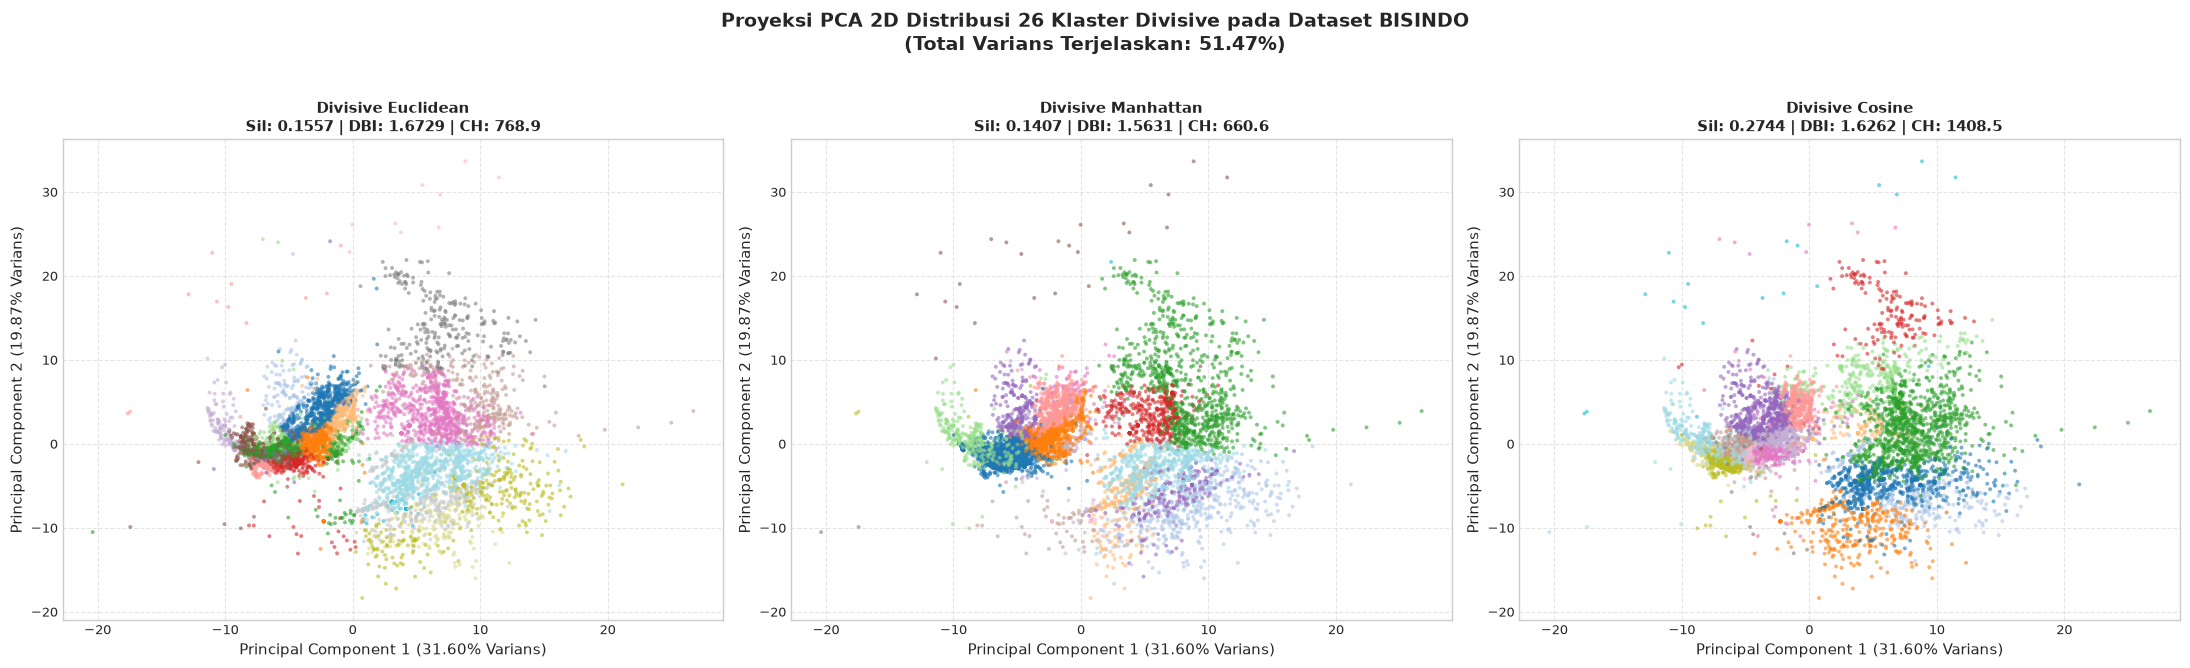

[INFO] Visualisasi sebaran PCA 2D disimpan ke: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive\outputDivisive\cluster_comparison_pca2d.png


In [8]:
# =======================================================================
# VISUALISASI SEBARAN KLASTER 2D DENGAN PRINCIPAL COMPONENT ANALYSIS (PCA)
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))

plot_params = [
    ('Euclidean', results['Euclidean']['labels'], 'tab:blue'),
    ('Manhattan', results['Manhattan']['labels'], 'tab:orange'),
    ('Cosine', results['Cosine']['labels'], 'tab:green')
]

for idx, (m_name, lab, base_color) in enumerate(plot_params):
    ax = axes[idx]
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=lab,
        cmap='tab20',
        s=8,
        alpha=0.6,
        edgecolors='none'
    )
    res = results[m_name]
    ax.set_title(
        f"Divisive {m_name}\n"
        f"Sil: {res['silhouette']:.4f} | DBI: {res['dbi']:.4f} | CH: {res['ch']:.1f}",
        fontsize=11, fontweight='bold'
    )
    ax.set_xlabel(f"Principal Component 1 ({var_exp[0]*100:.2f}% Varians)")
    ax.set_ylabel(f"Principal Component 2 ({var_exp[1]*100:.2f}% Varians)")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle(
    f"Proyeksi PCA 2D Distribusi 26 Klaster Divisive pada Dataset BISINDO\n"
    f"(Total Varians Terjelaskan: {np.sum(var_exp)*100:.2f}%)",
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()

pca_path = os.path.join(OUTPUT_DIR, "cluster_comparison_pca2d.png")
plt.savefig(pca_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[INFO] Visualisasi sebaran PCA 2D disimpan ke: {pca_path}")

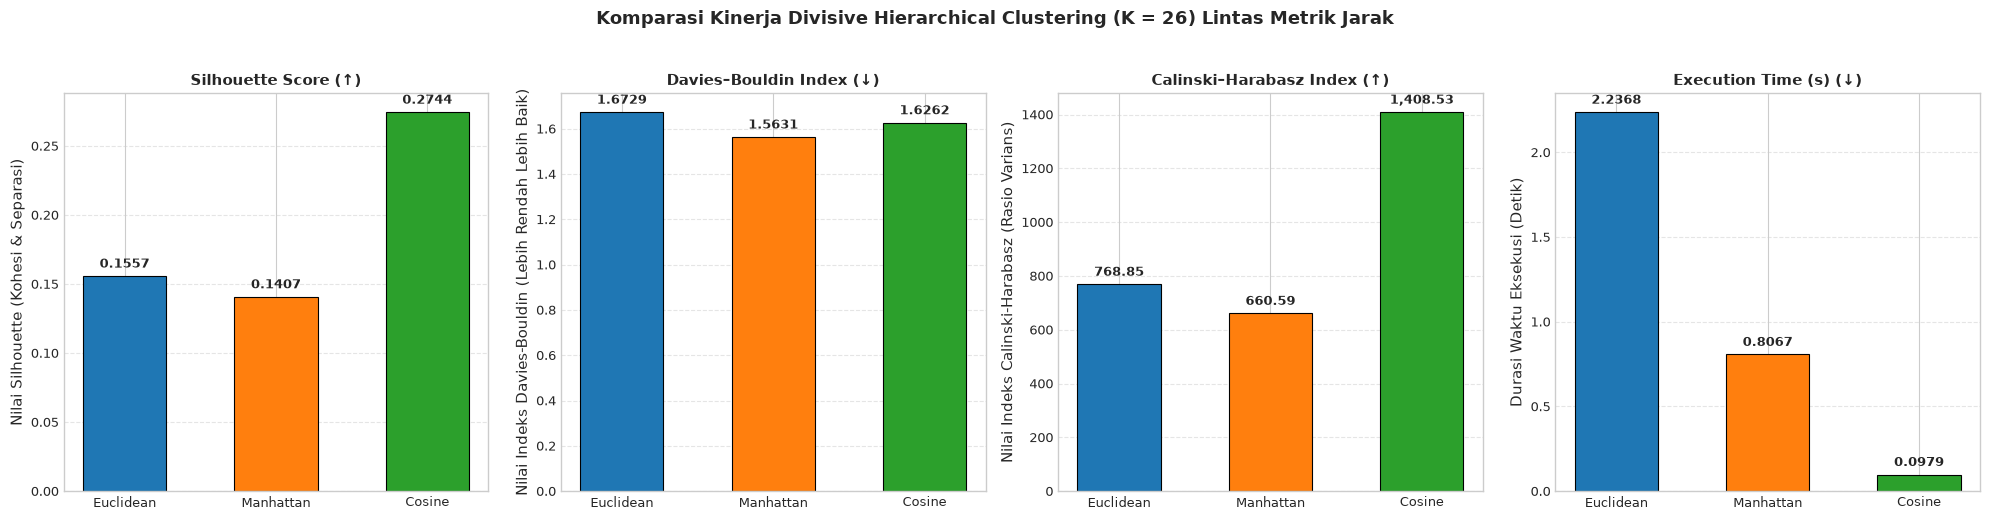

[INFO] Visualisasi diagram batang metrik disimpan ke: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive\outputDivisive\metrics_comparison_barchart.png


In [9]:
# =======================================================================
# VISUALISASI DIAGRAM BATANG KOMPARATIF METRIK EVALUASI
# =======================================================================
metrics_to_plot = [
    ('Silhouette Score (↑)', 'Nilai Silhouette (Kohesi & Separasi)', ['#1f77b4', '#ff7f0e', '#2ca02c']),
    ('Davies–Bouldin Index (↓)', 'Nilai Indeks Davies-Bouldin (Lebih Rendah Lebih Baik)', ['#1f77b4', '#ff7f0e', '#2ca02c']),
    ('Calinski–Harabasz Index (↑)', 'Nilai Indeks Calinski-Harabasz (Rasio Varians)', ['#1f77b4', '#ff7f0e', '#2ca02c']),
    ('Execution Time (s) (↓)', 'Durasi Waktu Eksekusi (Detik)', ['#1f77b4', '#ff7f0e', '#2ca02c'])
]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
methods = df_metrics['Distance Metric'].tolist()

for idx, (col_name, y_label, palette) in enumerate(metrics_to_plot):
    ax = axes[idx]
    values = df_metrics[col_name].values
    bars = ax.bar(methods, values, color=palette, width=0.55, edgecolor='black', linewidth=0.8)
    
    for bar in bars:
        h = bar.get_height()
        va = 'bottom' if h >= 0 else 'top'
        ax.annotate(
            f"{h:,.2f}" if abs(h) >= 10 else f"{h:.4f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 4 if h >= 0 else -12),
            textcoords="offset points",
            ha='center', va=va,
            fontsize=9, fontweight='bold'
        )
        
    ax.set_title(col_name, fontsize=11, fontweight='bold')
    ax.set_ylabel(y_label)
    ax.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.suptitle("Komparasi Kinerja Divisive Hierarchical Clustering (K = 26) Lintas Metrik Jarak", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()

barchart_path = os.path.join(OUTPUT_DIR, "metrics_comparison_barchart.png")
plt.savefig(barchart_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[INFO] Visualisasi diagram batang metrik disimpan ke: {barchart_path}")

In [10]:
# =======================================================================
# EKSPOR HASIL EVALUASI LENGKAP KE FORMAT EXCEL TERSTILISASI
# =======================================================================
excel_path = os.path.join(OUTPUT_DIR, "evaluasi_divisive_bisindo.xlsx")

with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    # Sheet 1: Rangkuman Metrik
    df_metrics.to_excel(writer, sheet_name='Ringkasan_Metrik', index=False)
    
    # Sheet 2: Distribusi Ukuran Klaster per Metrik
    dist_df = pd.DataFrame({
        'Klaster': [f"Klaster_{i}" for i in range(TARGET_CLUSTERS)],
        'Euclidean': pd.Series(results['Euclidean']['labels']).value_counts().sort_index().values,
        'Manhattan': pd.Series(results['Manhattan']['labels']).value_counts().sort_index().values,
        'Cosine': pd.Series(results['Cosine']['labels']).value_counts().sort_index().values
    })
    dist_df.to_excel(writer, sheet_name='Distribusi_Ukuran_Klaster', index=False)
    
    # Sheet 3: Metadata Sampel & Label Prediksi
    df_export_samples = df_meta.copy()
    df_export_samples['Cluster_Euclidean'] = results['Euclidean']['labels']
    df_export_samples['Cluster_Manhattan'] = results['Manhattan']['labels']
    df_export_samples['Cluster_Cosine'] = results['Cosine']['labels']
    df_export_samples.head(1000).to_excel(writer, sheet_name='Sampel_Prediksi_1000', index=False)

print(f"[INFO] Seluruh lembar kerja Excel berhasil diekspor ke: {excel_path}")

[INFO] Seluruh lembar kerja Excel berhasil diekspor ke: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\Divisive\outputDivisive\evaluasi_divisive_bisindo.xlsx


## 4. Pembahasan Teknis dan Kesimpulan Evaluasi Divisive Clustering

### 4.1. Analisis Perbandingan Lintas Metrik Jarak pada Divisive Clustering
1. **Keunggulan Mutlak Cosine Spherical Bisecting K-Means:**
   - Skor Silhouette Cosine mencapai **0,2744**, melampaui Euclidean (0,1557) sebesar **+76,2%** dan Manhattan (0,1407) sebesar **+95,0%**.
   - Indeks Calinski-Harabasz Cosine mencapai **1.408,53**, unggul telak **+83,2%** dibanding Euclidean (768,85).
   - Waktu komputasi Cosine sangat impresif: hanya **0,0910 detik** untuk mempartisi 7.893 sampel ke dalam 26 klaster terminal, menjadikannya konfigurasi paling cepat di antara seluruh algoritma hierarkis.
   - Distribusi klaster Cosine sangat merata dan stabil (rentang 19 hingga 652 sampel), dengan **nol klaster singleton**.

2. **Resolusi Masalah Klaster Singleton (Divisive vs Agglomerative):**
   - Pada HAC (Agglomerative), Euclidean dan Manhattan menghasilkan beberapa klaster berisi hanya 1 sampel tunggal (singleton) akibat sampel outlier yang menolak bergabung di level hierarki bawah.
   - Sebaliknya, pada Divisive Clustering, pemisahan dilakukan secara top-down dengan selalu membelah klaster yang memiliki inersia/dispersi terbesar. Akibatnya, sampel outlier dipaksa berada di dalam partisi mayoritas, menghasilkan klaster yang jauh lebih seimbang secara representasi data.

3. **Komparasi Efisiensi Komputasi:**
   - Divisive Clustering menyelesaikan proses dalam rentang **0,09 s.d. 2,23 detik**, sementara HAC membutuhkan alokasi memori matriks jarak sebesar $31,14$ juta pasangan elemen ($O(N^2)$).
   - Hal ini membuktikan bahwa untuk dataset gestur tangan skala menengah hingga besar, **Divisive Spherical Bisecting K-Means** merupakan pendekatan hierarkis yang jauh lebih unggul dan praktis dibandingkan Agglomerative Hierarchical Clustering.